# Active Subspaces for Sensitivity Analysis and Dimension Reduction of an Integrated Hydrologic Model

__Jennifer L. Jefferson__<sup>1,3</sup>, __James M. Gilbert__<sup>1,3</sup>, __Paul G. Constantine__<sup>2</sup> and __Reed M. Maxwell__<sup>1,3,4</sup>

<sup>1</sup> Colorado School of Mines, Hydrologic Science and Engineering Program, Golden, Colorado, USA<br>
<sup>2</sup> Colorado School of Mines, Department of Applied Mathematics and Statistics, Golden, Colorado, USA<br>
<sup>3</sup> Colorado School of Mines, Geology and Geological Engineering Department, Golden, Colorado, USA<br>
<sup>4</sup> Integrated Groundwater Modeling Center, Golden, Colorado, USA

Ryan Howard (2016 notebook)

<br>

This notebook summarizes the active subspace analysis of an integrated hydrologic model in [[1]][R1] for the single column domain, with the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later. It runs in Python 3 with numpy, scipy and matplotlib (see the repository's `requirements.txt`) in a few seconds. It uses no random numbers.

### Introduction

Weather and climate conditions are very dependent on energy fluxes into and out of the land surface. For example, evaporation and its eventual precipitation are dependent on latent heat fluxes (which redistribute water between land and the atmosphere) and sensible and ground heat fluxes (which determine the land surface and subsurface temperatures). It is difficult to directly measure such quantities, so hydrologic models have arisen to estimate these fluxes and their effects. These models can be complex, requiring 10 to 50 input parameters, and many of these parameters are difficult to measure accurately. This introduces uncertainty, and the effect of this uncertainty on model output is important to understand the model's efficacy.

### The Integrated Hydrologic Model

Integrated hydrologic models combine elements of groundwater and land surface models, accounting for water flow in saturated and unsaturated subsurface regions and variation in water table depth. These models should represent natural systems more realistically than the alternatives, but they have been historically less well studied. We'll be using the ParFlow-Common Land Model (PF-CLM) and studying 19 of its land surface parameters and how they relate to the heat fluxes. The PF-CLM is a set of PDEs and algebraic equations that can be numerically approximated to obtain estimates of latent, sensible, and ground heat fluxes. The 19 parameters are described in the table below, which follows Table 2 of [[1]][R1].

Variable|Name|Distribution|Default|Units
:-------|:---|:-----------|:------|:----
Maximum dew on canopy|dewmx|U(0.05, 0.15)|0.1|mm
Leaf area index (maximum)|lai|U(1, 4)|2|–
Leaf area index (minimum)|lai0|U(0.05, 3)|0.5|–
Stem area index|sai|U(0.5, 4)|4|–
Leaf and stem orientation index|xl|U(−0.3, 0.4)|−0.3|–
Leaf dimension|dleaf|U(0, 0.16)|0.04|m
Leaf reflectance (visible light)|rhol_vis|U(0.06, 0.13)|0.11|–
Leaf reflectance (near infrared light)|rhol_nir|U(0.35, 0.55)|0.58 <sup>a</sup>|–
Stem reflectance (visible light)|rhos_vis|U(0.3, 0.4)|0.36|–
Stem reflectance (near infrared light)|rhos_nir|U(0.5, 0.6)|0.58|–
Leaf transmittance (visible light)|taul_vis|U(0.01, 0.09)|0.07|–
Leaf transmittance (near infrared light)|taul_nir|U(0.1, 0.45)|0.25|–
Stem transmittance (visible light)|taus_vis|U(0.15, 0.25)|0.22|–
Stem transmittance (near infrared light)|taus_nir|U(0.3, 0.4)|0.38|–
Field capacity|fieldcap|U(0.3, 1)|1|–
Wilting point|wiltpt|U(0.1, 0.3)|0.1|–
Aerodynamic roughness length|z0m|bare soil: log z0m ~ N(−8.83, 1.47²)<br>grass: log z0m ~ N(−5.11, 0.52²) <sup>b</sup>|bare soil: 0.01<br>grass: 0.03|m
Soil color|soilcol|U(1, 8) <sup>c</sup>|2|–
Water table depth (below surface)|watertable|U(−10, −1)|none <sup>d</sup>|m

<sup>a</sup> Table 2 of [[1]][R1] gives the default 0.58, outside the range U(0.35, 0.55) given in the same table. The paper is inconsistent here, and which of the two values is in error is not known.<br>
<sup>b</sup> [[1]][R1] writes LN(−8.83, 1.47) and LN(−5.11, 0.52), "LogNormal(mean, standard deviation)". The two numbers are the mean $\mu$ and standard deviation $\sigma$ of log z0m, as the normalization $(\log z_{0m} - \mu)/\sigma$ in eq. (14) of [[1]][R1] shows. z0m is one parameter with a different distribution for each land cover; Table 2 of [[1]][R1] lists it on two rows.<br>
<sup>c</sup> Soil color is an integer class, 1 to 8, in the data files. As in [[1]][R1], it is normalized like the uniform inputs.<br>
<sup>d</sup> Table 2 of [[1]][R1] gives no default water table depth. The example at the end of this notebook uses −1 m, an illustrative choice.

Two domains were simulated in [[1]][R1]: a single column domain and a tilted-v domain, a primary difference being the absence (single column) or presence (tilted-v) of lateral water flow. Each domain was run with uniform cover of bare soil, which takes only three of the parameters (z0m, soilcol and watertable), or grass, which takes all 19, totaling 4 simulation classes. The simulations require several atmospheric inputs, for which meteorological data from the Little Washita watershed in Oklahoma was used, and subsurface parameters were set to nominal values since we are only concerned with sensitivity to surface parameters. The quantities of interest are the total latent, sensible and ground heat over the 144-hour forcing period.

### Active Subspaces

We'll be using active subspaces to study the relationship between the PF-CLM's parameters and our quantities of interest (latent, sensible, and ground heat). The active subspaces methodology identifies important directions in the input space, along which the output changes more than in the orthogonal directions (see [[2]][R2] and [[3]][R3] for more details). The important directions are defined by the eigenvectors of a matrix computed from the gradient of the output with respect to the normalized parameters, averaged over the density $\rho$ of the inputs. Here $\rho$ is the product of a uniform density on the bounded parameters and a normal density on log z0m (App. A.1 of [[1]][R1]). (Step 1 of the algorithm in §3 of [[1]][R1] says that all 19 inputs are drawn uniformly from a hypercube; that contradicts the paper's eq. (14) and App. A.1, and the data follow A.1.)

We don't have the gradient for the PF-CLM, and a finite difference approximation would be computationally infeasible (requiring 19 additional model evaluations per gradient sample). So we use the following algorithm ([[1]][R1] §3, [[3]][R3] Algorithm 1.3) to identify the _single_ most important direction in the input space: for $M$ sets of normalized inputs $\{\mathbf x_i\}_{i=1}^M$ and corresponding outputs $\{f_i\}$, use least squares to find the coefficients, $\hat a_0$ and $\hat{\mathbf a}$, of the linear model $f_i \approx \hat a_0 + \hat{\mathbf a}^T\mathbf x_i$; the important direction in the input space is $\hat{\mathbf w} = {\hat{\mathbf a}}/{\|\hat{\mathbf a}\|}$. If we observe a tight univariate trend when plotting $f_i$ vs $\hat{\mathbf w}^T\mathbf x_i$ (a _sufficient summary plot_), we can reasonably approximate $f(\mathbf x)\approx g(\hat{\mathbf w}^T\mathbf x)$, where $f$ represents the quantity of interest as a function of the inputs and $g$ is a function constructed from the pairs $(\hat{\mathbf w}^T\mathbf x_i,\ f_i)$.

The direction $\hat{\mathbf w}$ is a heuristic, and the sufficient summary plot is its check. If $f$ is linear, $\hat{\mathbf w}$ is the first eigenvector of the gradient-based matrix, but in general the two differ ([[3]][R3] §1.2). For standard normal inputs, Stein's lemma makes the least-squares slope $\hat{\mathbf a}$ an estimate of the average gradient $E[\nabla f]$. For uniform inputs, it recovers a direction of $f$ only under a linearity condition that the hypercube satisfies only in special cases (Li [[4]][R4]), and it can miss the direction entirely when $f$ is not monotonic ([[3]][R3] §1.3). The v1 library says so with a `validity.assumption` warning, which we print below.

The sign of $\hat{\mathbf w}$ is fixed, $\hat{\mathbf w} = \hat{\mathbf a}/\|\hat{\mathbf a}\|$, as in eq. (10) of [[1]][R1]: a positive weight means that increasing that input moves the active variable to the right. The v1 library returns this sign.

### The data

The data are 300 PF-CLM runs for each land cover, single column domain. They are later model runs than those behind the figures and tables of [[1]][R1], and they do not reproduce them: the fitted coefficients, the $R^2$ values, the ranking of the grass latent heat parameters and the example at the end all differ from the paper. Each difference is printed below beside the paper's value. The units and normalization of the output files are not recorded (see `DATA.md`). The constant terms of the quadratic fits below are 103 to 617 times those of the paper's Table 4, whose outputs are labeled W m⁻², with a different factor for each flux.

### References:

[[1]][R1] J.L. Jefferson, J.M. Gilbert, P.G. Constantine, R.M. Maxwell. _Active subspaces for sensitivity analysis and dimension reduction of an integrated hydrologic model_. Comput. Geosci., 83:127–138, 2015. doi:10.1016/j.cageo.2015.07.001. Reprinted in Comput. Geosci., 90:78–89, 2016, doi:10.1016/j.cageo.2015.11.002

[[2]][R2] P.G. Constantine, E. Dow, and Q. Wang. _Active subspace methods in theory and practice: applications to kriging surfaces_. SIAM J. Sci. Comput., 36(4):A1500–A1524, 2014. doi:10.1137/130916138

[[3]][R3] P.G. Constantine. _Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies_. SIAM, 2015. doi:10.1137/1.9781611973860

[[4]][R4] K.-C. Li. _Sliced inverse regression for dimension reduction_. J. Amer. Statist. Assoc., 86(414):316–327, 1991. doi:10.1080/01621459.1991.10475035

[R1]: https://doi.org/10.1016/j.cageo.2015.07.001
[R2]: https://doi.org/10.1137/130916138
[R3]: https://doi.org/10.1137/1.9781611973860
[R4]: https://doi.org/10.1080/01621459.1991.10475035

### Acknowledgments

This material is based upon work supported by the U.S. Department of Energy Office of Science, Office of Advanced Scientific Computing Research, Applied Mathematics program under Award Number DE-SC-0011077.

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import ticker
import active_subspaces as ac

t_start = time.perf_counter()

We read the inputs and outputs. The input files have a header row of parameter names, in an order different from the table; we reorder the columns as in the table. Only the first three output columns are used: total latent, sensible and ground heat (columns 3 and 4 of the output files are not documented; see `DATA.md`). The roughness length enters the analysis as log z0m.

In [2]:
def read_named(fn):
    """Read a space-separated file with one header row of quoted names."""
    with open(fn) as fh:
        names = [h.strip('"') for h in fh.readline().split()]
    return names, np.loadtxt(fn, skiprows=1, ndmin=2)


ORDER = {'grass': ['dewmx', 'lai', 'lai0', 'sai', 'xl', 'dleaf', 'rhol_vis', 'rhol_nir', 'rhos_vis',
                   'rhos_nir', 'taul_vis', 'taul_nir', 'taus_vis', 'taus_nir', 'fieldcap', 'wiltpt',
                   'z0m', 'soilcol', 'watertable'],
         'bare': ['z0m', 'soilcol', 'watertable']}
covers = ['bare', 'grass']
cover_title = {'bare': 'Bare Soil', 'grass': 'Grass'}
out_labels = ['Total Latent Heat', 'Total Sensible Heat', 'Total Ground Heat']
qois = ['LH', 'SH', 'GH']

X, F = {}, {}
for c in covers:
    header, data = read_named(f'SC_ScatterParameters_{c}.txt')
    X[c] = data[:, [header.index(n) for n in ORDER[c]]]
    X[c][:, ORDER[c].index('z0m')] = np.log(X[c][:, ORDER[c].index('z0m')])   # z0m -> log z0m
    F[c] = np.loadtxt(f'ScatterSummary_{c}.txt')[:, :3]                         # LH, SH, GH
    print(f'{cover_title[c]}: inputs {X[c].shape}, outputs {F[c].shape}')

Bare Soil: inputs (300, 3), outputs (300, 3)
Grass: inputs (300, 19), outputs (300, 3)


The input space is a product of independent blocks, given in the order of the data columns (`ac.Product`): uniform blocks with the bounds from the table, and a normal block for log z0m with the mean and variance of its land cover. v1 normalizes the uniform inputs to $[-1, 1]$ (eq. (13) of [[1]](https://doi.org/10.1016/j.cageo.2015.07.001)) and log z0m to $(\log z_{0m} - \mu)/\sigma$ (eq. (14)). Every sample lies inside the bounds of the uniform inputs.

In [3]:
lb = dict(zip(ORDER['grass'][:16] + ORDER['grass'][17:],
              [.05, 1, .05, .5, -.3, 0, .06, .35, .3, .5, .01, .1, .15, .3, .3, .1, 1, -10]))
ub = dict(zip(ORDER['grass'][:16] + ORDER['grass'][17:],
              [.15, 4, 3, 4, .4, .16, .13, .55, .4, .6, .09, .45, .25, .4, 1, .3, 8, -1]))
log_z0m = {'bare': (-8.83, 1.47), 'grass': (-5.11, .52)}    # mean and standard deviation of log z0m


def uniform(names):
    return ac.Uniform([lb[n] for n in names], [ub[n] for n in names], names=names)


space = {}
for c in covers:
    k = ORDER[c].index('z0m')                 # log z0m is column 16 (grass) or 0 (bare soil)
    mu, sd = log_z0m[c]
    blocks = [uniform(ORDER[c][:k])] if k > 0 else []
    blocks += [ac.Gaussian([mu], [sd**2], names=['log_z0m']), uniform(ORDER[c][k + 1:])]
    space[c] = ac.Product(blocks)
    XX = space[c].to_normalized(X[c])
    print(f'{cover_title[c]}: {[type(b).__name__ + str(b.dim) for b in space[c].blocks]}, '
          f'all samples inside: {space[c].contains(X[c]).all()}, '
          f'log z0m sample mean {X[c][:, k].mean():.2f} (mu {mu}), sd {X[c][:, k].std(ddof=1):.2f} (sigma {sd})')

Bare Soil: ['Gaussian1', 'Uniform2'], all samples inside: True, log z0m sample mean -8.94 (mu -8.83), sd 1.53 (sigma 1.47)
Grass: ['Uniform16', 'Gaussian1', 'Uniform2'], all samples inside: True, log z0m sample mean -5.10 (mu -5.11), sd 0.50 (sigma 0.52)


Now we compute the six one-dimensional subspaces, one for each combination of land cover (bare soil or grass) and heat flux (latent, sensible or ground), with the least-squares estimator above (`estimator="ols"`). The eigenvalue v1 reports is $\lambda_1 = \|\hat{\mathbf a}\|^2$. Each fit warns `validity.assumption` for the reason given above; we record the warnings and print them once.

In [4]:
def recorded(fn, **kw):
    """Call fn(**kw), recording warnings; return the result and the warning codes."""
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        result = fn(**kw)
    return result, [getattr(w.message, 'code', w.category.__name__) for w in caught], caught


sub, codes = {}, {}
for c in covers:
    for i, q in enumerate(qois):
        sub[c, q], codes[c, q], caught = recorded(ac.active_subspace, X=X[c], f=F[c][:, i],
                                                 space=space[c], estimator='ols', n=1)
print(f'warnings: {sorted(set(sum(codes.values(), [])))} in {sum(map(bool, codes.values()))} of 6 fits')
print(f'message: {caught[0].message}')
for c in covers:
    print(f'{cover_title[c]:>10}: lambda_1 = ' + ', '.join(f'{q} {sub[c, q].eigenvalues[0]:.6g}' for q in qois))

warnings: ['validity.assumption'] in 6 of 6 fits
message: outside the method's assumptions; estimator 'ols' on a product space: needs the linearity condition, which the cube satisfies only in special cases [Li1991] [validity.assumption]
 Bare Soil: lambda_1 = LH 1.98448e+10, SH 1.05702e+10, GH 2.06168e+09
     Grass: lambda_1 = LH 6.68147e+10, SH 7.68786e+10, GH 6.77473e+09


**Check against the 2016 notebook.** The 2016 notebook normalized the inputs by hand and solved the same least-squares problem with the 2016 library, which made the first component of $\hat{\mathbf w}$ positive. We repeat its computation with numpy and compare. The 2016 notebook printed no numbers; the values of $\|\hat{\mathbf a}\|^2$ below are those recomputed from its code ([docs/port-2026/Hydrology.md](../../docs/port-2026/Hydrology.md) §9). The directions agree up to sign, and the sign differs for three of the six cases: those panels of the 2016 figures are mirrored relative to this notebook and to [[1]](https://doi.org/10.1016/j.cageo.2015.07.001).

In [5]:
lam_2016 = {('bare', 'LH'): 1.98448e10, ('bare', 'SH'): 1.05702e10, ('bare', 'GH'): 2.06168e9,
            ('grass', 'LH'): 6.68147e10, ('grass', 'SH'): 7.68786e10, ('grass', 'GH'): 6.77473e9}
for c in covers:
    k = ORDER[c].index('z0m')
    uni = [j for j in range(len(ORDER[c])) if j != k]
    lo, hi = np.array([lb[ORDER[c][j]] for j in uni]), np.array([ub[ORDER[c][j]] for j in uni])
    XX = np.empty_like(X[c])
    XX[:, uni] = 2 * (X[c][:, uni] - lo) / (hi - lo) - 1               # the 2016 hand normalization
    XX[:, k] = (X[c][:, k] - log_z0m[c][0]) / log_z0m[c][1]
    for i, q in enumerate(qois):
        a = np.linalg.lstsq(np.hstack([np.ones((len(XX), 1)), XX]), F[c][:, i], rcond=None)[0][1:]
        w_2016 = a / np.linalg.norm(a) * np.sign(a[0])                   # 2016 sign: first component > 0
        w = sub[c, q].W1[:, 0]
        lam = sub[c, q].eigenvalues[0]
        print(f'{cover_title[c]:>10} {q}: lambda_1 = {lam:.6g}, 2016 {lam_2016[c, q]:.6g}, '
              f'|lambda_1 - |a|^2| / |a|^2 = {abs(lam - a @ a) / (a @ a):.1e}, '
              f'| |w.w_2016| - 1 | = {abs(abs(w @ w_2016) - 1):.1e}, '
              f'2016 panel {"mirrored" if w @ w_2016 < 0 else "same sign"}')

 Bare Soil LH: lambda_1 = 1.98448e+10, 2016 1.98448e+10, |lambda_1 - |a|^2| / |a|^2 = 6.2e-15, | |w.w_2016| - 1 | = 4.4e-16, 2016 panel same sign
 Bare Soil SH: lambda_1 = 1.05702e+10, 2016 1.05702e+10, |lambda_1 - |a|^2| / |a|^2 = 2.5e-15, | |w.w_2016| - 1 | = 0.0e+00, 2016 panel same sign
 Bare Soil GH: lambda_1 = 2.06168e+09, 2016 2.06168e+09, |lambda_1 - |a|^2| / |a|^2 = 2.3e-15, | |w.w_2016| - 1 | = 0.0e+00, 2016 panel mirrored
     Grass LH: lambda_1 = 6.68147e+10, 2016 6.68147e+10, |lambda_1 - |a|^2| / |a|^2 = 1.0e-15, | |w.w_2016| - 1 | = 0.0e+00, 2016 panel same sign
     Grass SH: lambda_1 = 7.68786e+10, 2016 7.68786e+10, |lambda_1 - |a|^2| / |a|^2 = 0.0e+00, | |w.w_2016| - 1 | = 2.2e-16, 2016 panel mirrored
     Grass GH: lambda_1 = 6.77473e+09, 2016 6.77473e+09, |lambda_1 - |a|^2| / |a|^2 = 8.4e-16, | |w.w_2016| - 1 | = 0.0e+00, 2016 panel mirrored


We plot the components of $\hat{\mathbf w}$ (the weights) for grass (blue) and bare soil (red) for each heat flux. See also Fig. 5 of [[1]](https://doi.org/10.1016/j.cageo.2015.07.001). The weights follow the paper's sign convention, so each panel has the paper's orientation, though the data differ (see below).

 Bare Soil LH: log z0m +0.71, soilcol +0.54, watertable +0.46
 Bare Soil SH: soilcol +0.85, watertable -0.40, log z0m +0.35
 Bare Soil GH: log z0m -0.89, soilcol +0.40, watertable +0.21
     Grass LH: fieldcap -0.56, lai +0.53, watertable +0.45, wiltpt -0.34, sai -0.23, dewmx +0.13
     Grass SH: taul_nir -0.60, rhol_nir -0.39, fieldcap +0.37, watertable -0.34, wiltpt +0.28, rhos_nir -0.24
     Grass GH: lai -0.69, sai -0.62, xl -0.28, log z0m -0.16, taul_nir +0.11, fieldcap +0.10


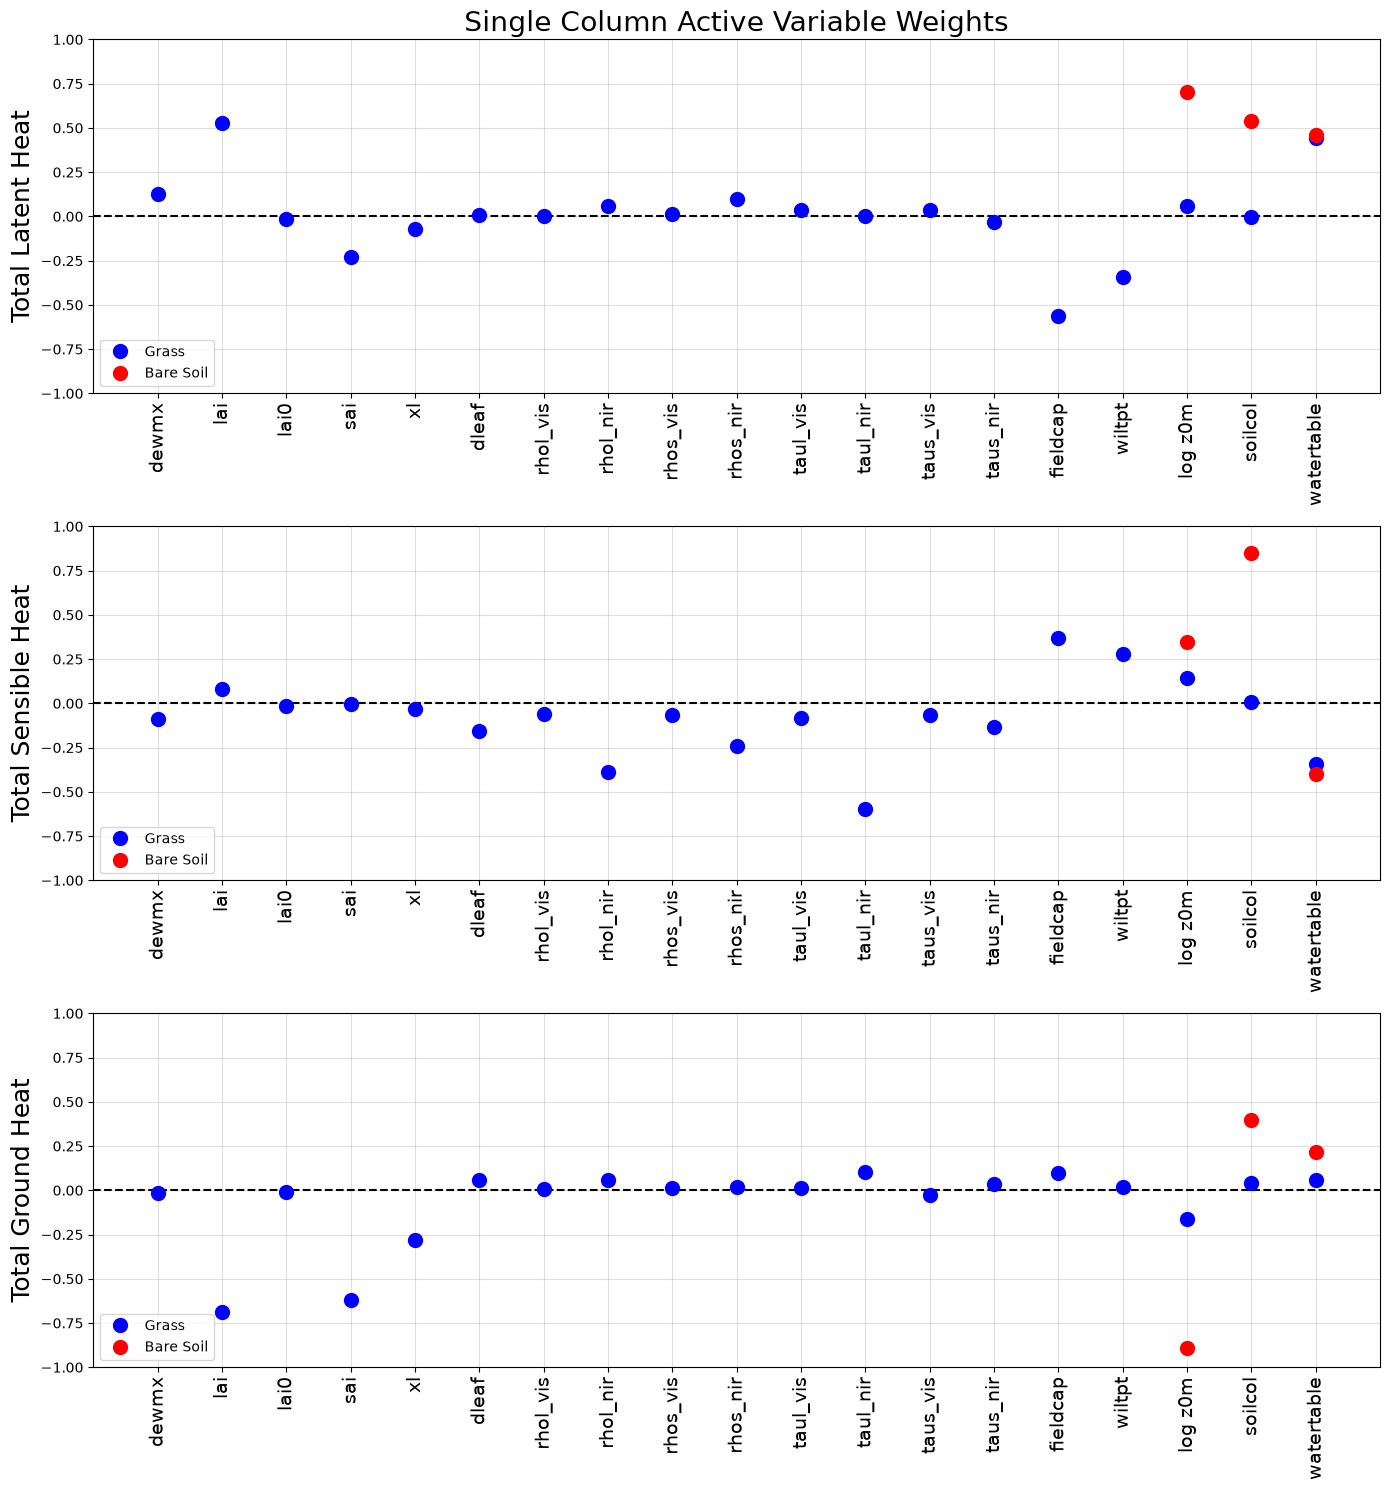

In [6]:
names = ORDER['grass']
ticks = [n if n != 'z0m' else 'log z0m' for n in names]
pos = {c: [names.index(n) + 1 for n in ORDER[c]] for c in covers}
m = len(names)

fig = plt.figure(figsize=(14, 15))
for i, q in enumerate(qois):
    ax = fig.add_subplot(3, 1, i + 1)
    if i == 0:
        ax.set_title('Single Column Active Variable Weights', fontsize=20)
    ax.set_ylim([-1, 1])
    ax.set_ylabel(out_labels[i], fontsize=18)
    ax.set_xlim([0, m + 1])
    ax.set_xticks(range(1, m + 1))
    ax.grid(True, alpha=.4)
    ax.hlines(0, 0, m + 1, linestyles='dashed', colors='k')
    ax.set_xticklabels(ticks, rotation='vertical', fontsize=14)
    ax.plot(pos['grass'], sub['grass', q].W1[:, 0], 'bo', ms=10, label='Grass')
    ax.plot(pos['bare'], sub['bare', q].W1[:, 0], 'ro', ms=10, label='Bare Soil')
    ax.legend(loc='lower left')
fig.tight_layout()

for c in covers:
    for q in qois:
        w = sub[c, q].W1[:, 0]
        top = np.argsort(-np.abs(w))[:6]
        print(f'{cover_title[c]:>10} {q}: ' + ', '.join(f'{ticks[names.index(ORDER[c][j])]} {w[j]:+.2f}' for j in top))

The magnitude of each component tells us how sensitive the output is to that variable; the output tends to change more with variables with large-magnitude components compared to those with small-magnitude components. The sign says in which direction: increasing an input with a positive weight moves the active variable to the right.

- **Bare soil.** All three parameters carry large weights for every flux. log z0m (aerodynamic roughness length) has the largest weight for latent and ground heat, and soil color for sensible heat, as [[1]](https://doi.org/10.1016/j.cageo.2015.07.001) finds (§4.1).
- **Grass, latent heat.** Field capacity, lai (leaf area index), water table depth and wilting point have the largest weights, then sai (stem area index); the other parameters have weights close to 0. [[1]](https://doi.org/10.1016/j.cageo.2015.07.001) ranks lai, dewmx (dmx), field capacity, z0m, water table and wilting point, so in these data dewmx and z0m matter much less (compared below).
- **Grass, sensible heat.** taul_nir (near-infrared leaf transmittance) has the largest weight, as in [[1]](https://doi.org/10.1016/j.cageo.2015.07.001), followed by rhol_nir, field capacity, water table depth and wilting point. [[1]](https://doi.org/10.1016/j.cageo.2015.07.001) also names dewmx and sai, which have small weights here.
- **Grass, ground heat.** lai and sai dominate, followed by xl and log z0m. [[1]](https://doi.org/10.1016/j.cageo.2015.07.001) names lai, sai and z0m.
- **Signs.** The lai weight is positive for latent heat and negative for ground heat, as the paper says (p. 18): more leaf area means more evaporation and transpiration and less radiation reaching the ground.

In [7]:
paper_lh_rank = ['lai', 'dewmx', 'fieldcap', 'z0m', 'watertable', 'wiltpt']    # [1] Sec. 4.1
w = sub['grass', 'LH'].W1[:, 0]
rank = list(np.argsort(-np.abs(w)))
print('grass latent heat, rank (1 = largest |weight|) of the six parameters the paper lists first:')
for n in paper_lh_rank:
    j = names.index(n)
    print(f'  {n:>10}: paper rank {paper_lh_rank.index(n) + 1}, here rank {rank.index(j) + 1:2d}, weight {w[j]:+.2f}')
print(f'grass lai weight: latent heat {sub["grass", "LH"].W1[1, 0]:+.2f} (> 0), '
      f'ground heat {sub["grass", "GH"].W1[1, 0]:+.2f} (< 0)')

grass latent heat, rank (1 = largest |weight|) of the six parameters the paper lists first:
         lai: paper rank 1, here rank  2, weight +0.53
       dewmx: paper rank 2, here rank  6, weight +0.13
    fieldcap: paper rank 3, here rank  1, weight -0.56
         z0m: paper rank 4, here rank  9, weight +0.06
  watertable: paper rank 5, here rank  3, weight +0.45
      wiltpt: paper rank 6, here rank  4, weight -0.34
grass lai weight: latent heat +0.53 (> 0), ground heat -0.69 (< 0)


Now we plot the quantities of interest against the active variable $\hat{\mathbf w}^T\mathbf x$ (blue dots), with a quadratic response surface $g(y) = C_0 + C_1 y + C_2 y^2$ (black line), as in eq. (12) of [[1]](https://doi.org/10.1016/j.cageo.2015.07.001). The bands are the 95% confidence limits for the mean (dark) and the 95% prediction limits for a new run (light), the least-squares limits $g(y) \pm t\, s\sqrt{c + \mathbf b(y)^T(\mathbf B^T\mathbf B)^{-1}\mathbf b(y)}$ with $\mathbf b(y) = (1, y, y^2)$, $\mathbf B$ the design matrix of the 300 runs, $s$ the residual standard error, $t$ the Student $t$ quantile with $M - 3$ degrees of freedom, and $c = 0$ (confidence) or 1 (prediction). They are drawn only over the range of the data, and treat $\hat{\mathbf w}$ as fixed. (The 2016 notebook used the leverage of a straight-line fit and the normal quantile 2.33, and drew the bands out to $\pm 3$; Fig. 5 of [[1]](https://doi.org/10.1016/j.cageo.2015.07.001) shows the 95% confidence band only.) `PolynomialSurrogate.interval` gives these limits on the active variable, and `ac.predict_interval` at physical inputs.

Each panel shows the in-sample $R^2$, which is the measure of the 2016 notebook and of [[1]](https://doi.org/10.1016/j.cageo.2015.07.001). The leave-one-out $R^2$ (`loo_r_squared`) is printed below it; it is slightly lower.

In [8]:
paper_table4 = {('bare', 'LH'): (8.41e3, 1.11e3, 1.04e2, .98), ('bare', 'SH'): (1.81e3, 5.27e2, -1.57e2, .92),
                ('bare', 'GH'): (9.10e2, 2.05e2, 1.01e1, .99), ('grass', 'LH'): (7.22e3, 1.53e3, 3.17e2, .89),
                ('grass', 'SH'): (2.28e3, 1.54e3, -1.48e2, .84), ('grass', 'GH'): (3.54e2, 2.95e2, 7.36e1, .95)}
r2_2016 = {('bare', 'LH'): .95, ('bare', 'SH'): .92, ('bare', 'GH'): .99,
           ('grass', 'LH'): .82, ('grass', 'SH'): .83, ('grass', 'GH'): .96}     # printed on the 2016 figure

rs, r2 = {}, {}
for c in covers:
    for i, q in enumerate(qois):
        f = F[c][:, i]
        rs[c, q], cw, _ = recorded(ac.fit_surrogate, X=X[c], f=f, subspace=sub[c, q], kind='poly', degree=2)
        if cw:
            print(f'{c} {q}: {cw}')
        r2[c, q] = 1 - np.sum(rs[c, q].residuals**2) / np.sum((f - f.mean())**2)

print(f'{"":>9}{"C0":>11}{"C1":>11}{"C2":>11}{"R2":>6}{"LOO R2":>8}{"2016 R2":>9}  |  paper: '
      f'{"C0":>9}{"C1":>9}{"C2":>10}{"R2":>6}{"C0 ratio":>10}')
for c in covers:
    for q in qois:
        coef = dict(zip(map(int, rs[c, q].indices[:, 0]), rs[c, q].coefficients))
        p = paper_table4[c, q]
        print(f'{c + " " + q:>9}{coef[0]:11.3e}{coef[1]:11.3e}{coef[2]:11.3e}{r2[c, q]:6.2f}'
              f'{rs[c, q].loo_r_squared:8.3f}{r2_2016[c, q]:9.2f}  |  {"":>7}{p[0]:9.2e}{p[1]:9.2e}{p[2]:10.2e}'
              f'{p[3]:6.2f}{coef[0] / p[0]:10.0f}')

                  C0         C1         C2    R2  LOO R2  2016 R2  |  paper:        C0       C1        C2    R2  C0 ratio
  bare LH  1.439e+06  1.413e+05  7.891e+03  0.95   0.951     0.95  |          8.41e+03 1.11e+03  1.04e+02  0.98       171
  bare SH  7.437e+05  1.022e+05  5.317e+03  0.92   0.915     0.92  |          1.81e+03 5.27e+02 -1.57e+02  0.92       411
  bare GH  2.709e+05  4.524e+04  1.329e+03  0.99   0.992     0.99  |          9.10e+02 2.05e+02  1.01e+01  0.99       298
 grass LH  7.406e+05  2.408e+05  9.870e+04  0.82   0.814     0.82  |          7.22e+03 1.53e+03  3.17e+02  0.89       103
 grass SH  1.306e+06  2.750e+05 -2.403e+04  0.83   0.822     0.83  |          2.28e+03 1.54e+03 -1.48e+02  0.84       573
 grass GH  2.183e+05  8.365e+04  1.558e+04  0.96   0.963     0.96  |          3.54e+02 2.95e+02  7.36e+01  0.95       617


 Bare Soil LH: 95% of the 300 runs inside their 95% prediction limits (dof 297); C1 > 0
 Bare Soil SH: 96% of the 300 runs inside their 95% prediction limits (dof 297); C1 > 0
 Bare Soil GH: 95% of the 300 runs inside their 95% prediction limits (dof 297); C1 > 0
     Grass LH: 94% of the 300 runs inside their 95% prediction limits (dof 297); C1 > 0
     Grass SH: 96% of the 300 runs inside their 95% prediction limits (dof 297); C1 > 0
     Grass GH: 96% of the 300 runs inside their 95% prediction limits (dof 297); C1 > 0


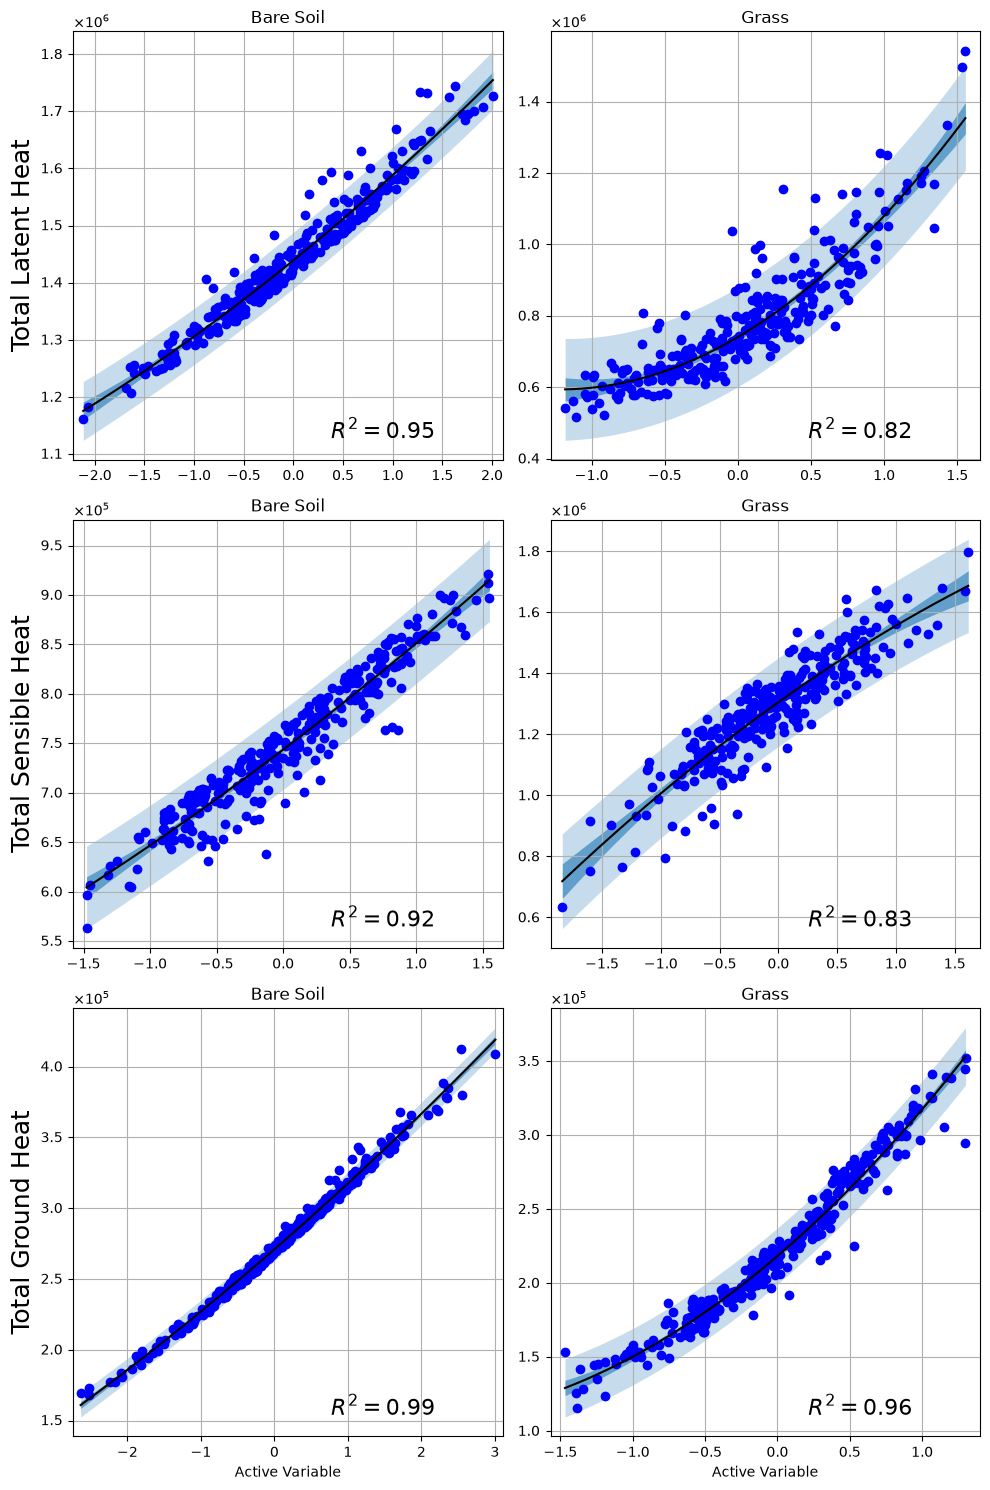

In [9]:
level = .95
fig = plt.figure(figsize=(10, 15))
for i, q in enumerate(qois):
    for col, c in enumerate(covers):
        ax = fig.add_subplot(3, 2, 2 * i + col + 1)
        ax.set_title(cover_title[c])
        if col == 0:
            ax.set_ylabel(out_labels[i], fontsize=18)
        if i == 2:
            ax.set_xlabel('Active Variable')
        ax.grid(True)
        y = rs[c, q].Y[:, 0]
        yy = np.linspace(y.min(), y.max(), 500)
        clo, chi = rs[c, q].interval(yy[:, None], level=level, kind='confidence')
        plo, phi = rs[c, q].interval(yy[:, None], level=level, kind='prediction')
        ax.fill_between(yy, plo, phi, color='C0', alpha=.25, linewidth=0)
        ax.fill_between(yy, clo, chi, color='C0', alpha=.6, linewidth=0)
        ax.plot(y, F[c][:, i], 'bo', ms=6)
        ax.plot(yy, rs[c, q].evaluate(yy[:, None]), 'k-', lw=1.5)
        ax.set_xlim(y.min() - .1, y.max() + .1)
        ax.text(.6, .05, rf'$R^2 = {r2[c, q]:.2f}$', transform=ax.transAxes, fontsize=16)
        formatter = ticker.ScalarFormatter(useMathText=True)
        formatter.set_scientific(True)
        formatter.set_powerlimits((-1, 1))
        ax.yaxis.set_major_formatter(formatter)
fig.tight_layout()

for c in covers:
    for i, q in enumerate(qois):
        iv = ac.predict_interval(rs[c, q], X[c], level=level, kind='prediction')
        inside = np.mean((F[c][:, i] >= iv.lower) & (F[c][:, i] <= iv.upper))
        print(f'{cover_title[c]:>10} {q}: {inside:.0%} of the 300 runs inside their 95% prediction limits '
              f'(dof {iv.dof}); C1 {"> 0" if rs[c, q].coefficients[list(rs[c, q].indices[:, 0]).index(1)] > 0 else "<= 0"}')

Every flux shows a univariate trend in the active variable, and the quadratic fits it well: the in-sample $R^2$ values equal those on the 2016 figure. $C_1 > 0$ in all six fits, as in Table 4 of [[1]](https://doi.org/10.1016/j.cageo.2015.07.001), because $\hat{\mathbf w}$ points along $\hat{\mathbf a}$. The fits are tighter for bare soil than for grass, and for ground heat than for latent and sensible heat. One physical explanation is the water table: its weight is lower for ground heat than for latent and sensible heat. Water table depth can heavily influence energy fluxes because conditions can change from dry to moist or vice-versa within a short time; these variations could introduce nonlinear behavior that we can't capture with linear models.

These are later runs than those of [[1]](https://doi.org/10.1016/j.cageo.2015.07.001), and the numbers differ (table above). The $R^2$ values for latent heat are lower here than in Table 4 of [[1]](https://doi.org/10.1016/j.cageo.2015.07.001), for bare soil and for grass; the other four agree within 0.01. The sign of $C_2$ differs for bare soil sensible heat. The ratio of $C_0$ to the paper's is not one constant: it ranges from 103 to 617 over the six fluxes, so the files differ from the paper's runs by more than a change of units. (In Table A1 of [[1]](https://doi.org/10.1016/j.cageo.2015.07.001) the quadratic $R^2$ for bare soil ground heat is below the linear $R^2$, which cannot happen for nested least-squares fits on the same data; we do not compare with that table.)

### Using the summary plot

Summary plots and response surfaces can be used for several purposes. For example, suppose we fixed the grass parameters at their default values (Table 2 of [[1]](https://doi.org/10.1016/j.cageo.2015.07.001); water table depth −1 m, our illustrative choice) and we were interested in the effect of increasing or decreasing the leaf area index (lai) by 1. It is straightforward to find the active variable values associated with these cases and evaluate the response surface at these values for predictions of the effects, and this can be easily visualized because of the low-dimensional nature of the subspace (see also Fig. 8 of [[1]](https://doi.org/10.1016/j.cageo.2015.07.001)).

The default point is not inside the sampled input space. rhol_nir = 0.58 is above its range (footnote a of the table), and the grass default z0m = 0.03 m is far in the tail of its distribution and above every sampled value. v1's `predict_interval` refuses such a point, so we evaluate the quadratic on the active variable directly, and the predictions below are extrapolations in the inputs.

In [10]:
c, q = 'grass', 'LH'
w, g = sub[c, q].W1[:, 0], rs[c, q]
x_nom = np.array([.1, 2, .5, 4, -.3, .04, .11, .58, .36, .58, .07, .25, .22, .38, 1, .1, np.log(.03), 2, -1])
k = names.index('z0m')
print(f'default inside the sampled box: {bool(space[c].contains(x_nom[None])[0])}')
try:
    ac.predict_interval(g, x_nom[None])
except ac.InputError as e:
    print(f'predict_interval: {e}')
print(f'default log z0m = {x_nom[k]:.3f}: {(x_nom[k] - log_z0m[c][0]) / log_z0m[c][1]:.2f} standard deviations above the mean; '
      f'largest sampled z0m = {np.exp(X[c][:, k].max()):.3f} m')

lai = {}
for v in (1, 2, 3):
    x = x_nom.copy()
    x[names.index('lai')] = v
    y = (space[c].to_normalized(x[None]) @ w)[0]
    lai[v] = (y, g.evaluate([[y]])[0])
y_nom, f_nom = lai[2]
print(f'active variable at the default point: {y_nom:.3f} (paper 0.28); range of the 300 runs '
      f'[{g.Y.min():.2f}, {g.Y.max():.2f}]')
paper_pct = {1: -7.5, 3: 8.5}
for v in (1, 3):
    print(f'lai = {v}: active variable {lai[v][0]:.3f}, latent heat {lai[v][1]:.4g}, '
          f'change {100 * (lai[v][1] / f_nom - 1):+.1f}% (paper {paper_pct[v]:+.1f}%)')

default inside the sampled box: False
predict_interval: X: 1 of 1 rows lie outside the support; first: row 0, input 'rhol_nir' (column 7) = 0.58 > upper 0.55 [input.out_of_space]
default log z0m = -3.507: 3.08 standard deviations above the mean; largest sampled z0m = 0.029 m
active variable at the default point: 0.236 (paper 0.28); range of the 300 runs [-1.18, 1.55]
lai = 1: active variable -0.114, latent heat 7.144e+05, change -11.0% (paper -7.5%)
lai = 3: active variable 0.587, latent heat 9.161e+05, change +14.1% (paper +8.5%)


We can also use response surfaces for the inverse problem: we observe data, use the response surface to find the active variable value(s) that we expect to produce our observations, and invert the map from inputs to the active variable to find sets of input values that would produce what we observe. There are infinitely many input combinations with the same active variable value; choosing among them needs more data or a regularization ([[1]](https://doi.org/10.1016/j.cageo.2015.07.001) §4.3). No observation is available for this period ([[1]](https://doi.org/10.1016/j.cageo.2015.07.001) §4.3), so we take an illustrative "observed" value: the upper quartile of the 300 grass latent heat runs. Within the range of the data the quadratic is increasing, so the observation determines one active variable value. The active variable values whose 95% prediction limits contain the observation give a range for it.

In the left panel the dotted lines mark the default point, and the shaded bands show the range of active variable and latent heat as lai goes from 1 to 3. In the right panel the arrows go from the observation to the curve and down to the active variable, and the shaded band is the range just described. The dashed parts of the curve lie outside the range of the data.

illustrative observation 8.493e+05: active variable 0.389; 95% prediction limits contain it for active variable in [-0.133, 0.781]


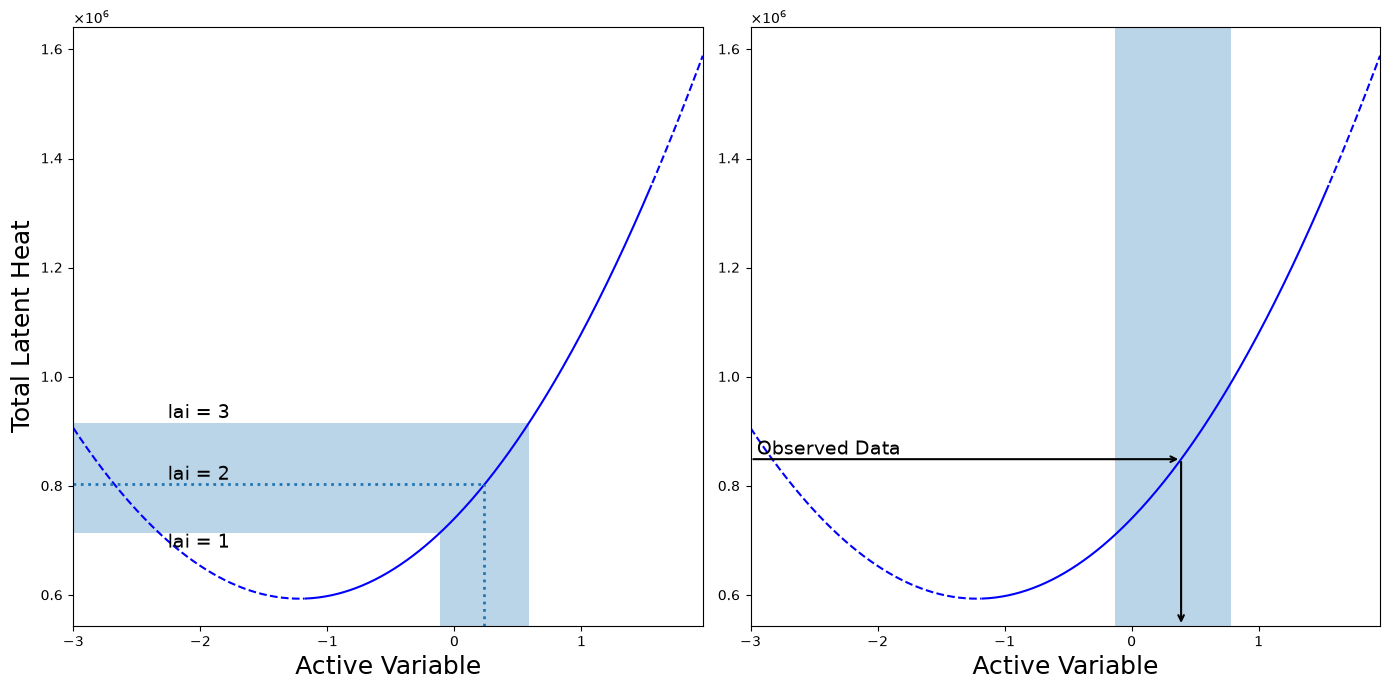

In [11]:
f_obs = np.percentile(F[c][:, 0], 75)
C = dict(zip(map(int, g.indices[:, 0]), g.coefficients))
roots = np.roots([C[2], C[1], C[0] - f_obs]).real
y_obs = roots[(roots >= g.Y.min()) & (roots <= g.Y.max())][0]
yy = np.linspace(g.Y.min(), g.Y.max(), 2001)
plo, phi = g.interval(yy[:, None], level=level, kind='prediction')
consistent = yy[(plo <= f_obs) & (f_obs <= phi)]
print(f'illustrative observation {f_obs:.4g}: active variable {y_obs:.3f}; '
      f'95% prediction limits contain it for active variable in [{consistent.min():.3f}, {consistent.max():.3f}]')

x_lo = min(-3, g.Y.min())
x_hi = max(lai[3][0], g.Y.max()) + .4
xs = np.linspace(x_lo, x_hi, 500)
inside = (xs >= g.Y.min()) & (xs <= g.Y.max())
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax in axes:
    curve = g.evaluate(xs[:, None])
    ax.plot(xs, np.where(inside, curve, np.nan), 'b-')
    ax.plot(xs, np.where(inside, np.nan, curve), 'b--')
    ax.set_xlim(x_lo, x_hi)
    ax.set_xlabel('Active Variable', fontsize=18)
    formatter = ticker.ScalarFormatter(useMathText=True)
    formatter.set_scientific(True)
    formatter.set_powerlimits((-1, 1))
    ax.yaxis.set_major_formatter(formatter)
bottom = axes[0].get_ylim()[0]

# left: the effect of changing lai by 1
ax = axes[0]
ax.set_ylabel(out_labels[0], fontsize=18)
ax.axhspan(lai[1][1], lai[3][1], xmin=0, xmax=(lai[3][0] - x_lo) / (x_hi - x_lo), alpha=.3, linewidth=0)
ax.fill_between([lai[1][0], lai[3][0]], bottom, [lai[1][1], lai[1][1]], alpha=.3, linewidth=0)
ax.hlines(f_nom, x_lo, y_nom, linestyles='dotted', linewidth=2)
ax.vlines(y_nom, bottom, f_nom, linestyles='dotted', linewidth=2)
for v in (1, 2, 3):
    ax.text(x_lo + .15 * (x_hi - x_lo), lai[v][1], f'lai = {v}', fontsize=14,
            va='top' if v == 1 else 'bottom')
ax.set_ylim(bottom=bottom)

# right: the inverse problem
ax = axes[1]
ax.set_ylim(axes[0].get_ylim())
ax.axvspan(consistent.min(), consistent.max(), alpha=.3, linewidth=0)
ax.annotate('', xy=(y_obs, f_obs), xytext=(x_lo, f_obs), arrowprops=dict(arrowstyle='->', lw=1.5))
ax.annotate('', xy=(y_obs, ax.get_ylim()[0]), xytext=(y_obs, f_obs), arrowprops=dict(arrowstyle='->', lw=1.5))
ax.text(x_lo + .05, f_obs, 'Observed Data', fontsize=14, va='bottom')
fig.tight_layout()

In these data, changing lai by one unit from the default changes the predicted latent heat by more than the paper's −7.5% / +8.5%, and the default point sits at a different active variable value than the paper's 0.28 (both printed above). The default point lies outside the sampled input space, so the numbers are extrapolations; they illustrate the method, not a property of PF-CLM.

The presence of an exploitable active subspace in this model serves as a proof-of-concept in the application of this methodology to hydrologic models. Active subspaces may be present in other hydrologic models for various domains, climate conditions, and sets of input parameters. The dimension reduction provided by these methods, especially for expensive, high-dimensional models, could aid in making accurate and timely predictions, optimizing output over the input space, or calibrating parameters, and if a sufficiently accurate approximation is found in the active subspace for a particular case, expensive simulation could be eschewed altogether in that case.

In [12]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 12.0 s
